# Bài tập nhóm — Đề 3: Dự đoán độ trễ từ kích thước gói tin và tải mạng

| Thông tin | |
|---|---|
| **Môn học** | Phương pháp thống kê dữ liệu (Chương 6, 7) |
| **Đề được giao** | Đề 3 — Dự đoán độ trễ từ kích thước gói tin và tải mạng |
| **Nhóm** | ……………………………… |
| **Thành viên** (họ tên – MSSV) | ……………………………… |
| **Giảng viên** | ……………………………… |
| **Ngày nộp** | ……………………………… |

**Công cụ:** Python (pandas, numpy, scipy, statsmodels, matplotlib), chạy trong Jupyter Notebook.

**Mục lục:** Yêu cầu 1 (thiết kế, sinh dữ liệu) · Yêu cầu 2 (hồi quy đơn) · Yêu cầu 3 (hồi quy bội) · Yêu cầu 4 (ý nghĩa hệ số) · Yêu cầu 5 (kiểm định, so sánh mô hình) · Yêu cầu 6 (dự đoán) · Yêu cầu 7 (yếu tố chưa xét, giới hạn) · Kết luận · Phụ lục (đánh giá phương pháp)

**Bài toán:** nhóm vận hành mạng muốn dự đoán độ trễ $Y$ (ms) và cần biết hai yếu tố **kích thước gói tin** $x_1$ (byte) và **tải mạng** $x_2$ (%) ảnh hưởng thế nào, cùng lúc chứ không riêng lẻ.

**Câu hỏi nghiên cứu của nhóm:**
1. Mỗi yếu tố có thật sự ảnh hưởng đến độ trễ không?
2. Nếu chỉ dùng kích thước gói tin thì thiếu sót gì?
3. Dự đoán độ trễ khi gói 1000 byte, tải 60% được bao nhiêu và đáng tin đến đâu?

**Quy ước:** mức ý nghĩa 5%, tin cậy 95%; dữ liệu là **dữ liệu mô phỏng**; có lưu seed và dữ liệu gốc để chạy lại ra cùng kết quả. Khi phân tích, nhóm chỉ ước lượng từ mẫu, không đưa các tham số dùng để sinh dữ liệu vào bước ước lượng.

**Các bước:** (1) thiết kế và sinh dữ liệu → (2) hồi quy đơn → (3) hồi quy bội → (4) giải thích hệ số → (5) kiểm định, so sánh hai mô hình → (6) dự đoán → (7) hạn chế → kết luận.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats

import sys, scipy, matplotlib
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| statsmodels", sm.__version__, "| matplotlib", matplotlib.__version__)

SEED = 2026          # hạt giống ngẫu nhiên, ghi rõ để chạy lại ra cùng kết quả
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
MAU = {20: "tab:blue", 50: "tab:orange", 80: "tab:green"}   # màu cố định cho 3 mức tải

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2


## Yêu cầu 1. Bảng thiết kế và sinh dữ liệu

### Thiết kế
Đề cho $x_1 \in \{200, 500, 800, 1100, 1400\}$ byte và $x_2 \in \{20, 50, 80\}\%$. Ghép đủ các mức: $5 \times 3 = 15$ tổ hợp. Mỗi tổ hợp lấy 4 quan sát nên có $15 \times 4 = 60$ quan sát.

Mô hình sinh dữ liệu: $Y = 5 + 0{,}005x_1 + 0{,}1x_2 + \varepsilon$, $\varepsilon \sim N(0; 2^2)$, các $\varepsilon$ độc lập.

In [2]:
x1_muc = [200, 500, 800, 1100, 1400]
x2_muc = [20, 50, 80]

thiet_ke = pd.DataFrame([(a, b, 4) for a in x1_muc for b in x2_muc],
                        columns=["x1 (byte)", "x2 (%)", "Số quan sát"])
thiet_ke.index = range(1, 16)
thiet_ke.index.name = "Tổ hợp"
thiet_ke

,x1 (byte),x2 (%),Số quan sát
Tổ hợp,,,
1,200,20,4
2,200,50,4
3,200,80,4
4,500,20,4
5,500,50,4
6,500,80,4
7,800,20,4
8,800,50,4
9,800,80,4


In [3]:
# Bảng chéo: mỗi ô là số quan sát của tổ hợp (x1, x2)
pd.crosstab(np.repeat(x1_muc, 12), np.tile(np.repeat(x2_muc, 4), 5), rownames=["x1 (byte)"], colnames=["x2 (%)"])

x2 (%),20,50,80
x1 (byte),,,
200,4,4,4
500,4,4,4
800,4,4,4
1100,4,4,4
1400,4,4,4


### Vì sao chọn thiết kế này (lợi ích)
| Lợi ích | Giải thích |
|---|---|
| **Cân bằng** | Mỗi mức $x_1$ đều được đo ở đủ cả 3 mức tải với số lần bằng nhau (và ngược lại). |
| **Hai biến không tương quan** | Vì cân bằng nên $\text{corr}(x_1, x_2) = 0$. Khi đưa cả hai vào mô hình, hệ số của từng biến không bị lẫn vào nhau. |
| **Phủ rộng khoảng cần xét** | 5 mức $x_1$ và 3 mức $x_2$ trải đều, nên đường hồi quy được ước lượng ổn định trong cả khoảng 200–1400 byte và 20–80%. |
| **Có đo lặp** | Mỗi tổ hợp 4 lần giúp thấy mức dao động ngẫu nhiên của độ trễ khi điều kiện giống hệt nhau. |

In [4]:
# Sinh dữ liệu: lặp mỗi tổ hợp 4 lần
df = thiet_ke.loc[thiet_ke.index.repeat(4), ["x1 (byte)", "x2 (%)"]].reset_index(drop=True)
df.columns = ["x1", "x2"]

eps = np.random.normal(0, 2, size=len(df))                 # sai số N(0; 2^2), độc lập
df["y"] = 5 + 0.005 * df["x1"] + 0.1 * df["x2"] + eps      # độ trễ (ms)
df.to_csv("du_lieu_de3.csv", index=False)                  # lưu dữ liệu gốc

print("Số quan sát:", len(df))
print("Tương quan giữa x1 và x2:", round(df["x1"].corr(df["x2"]), 4), "(bằng 0 nghĩa là hai biến độc lập nhau)")
df.head(8)

Số quan sát: 60
Tương quan giữa x1 và x2: 0.0 (bằng 0 nghĩa là hai biến độc lập nhau)


,x1,x2,y
0,200,20,7.136563
1,200,20,5.214252
2,200,20,8.623141
3,200,20,7.973530
4,200,50,13.899415
5,200,50,11.596305
6,200,50,9.340208
7,200,50,7.807683


### Kiểm tra dữ liệu vừa sinh
Trước khi phân tích, nhóm xem lại dữ liệu: giá trị nhỏ nhất, lớn nhất, các phân vị, và kiểm tra xem sai số sinh ra có đúng dạng $N(0; 2^2)$ không.

*Lưu ý:* bước này chỉ **kiểm tra bộ sinh dữ liệu** nên có dùng sai số $\varepsilon$ đã sinh. Từ Yêu cầu 2 trở đi, nhóm chỉ dùng $x_1, x_2, y$ và ước lượng từ mẫu, không thay tham số đã biết vào bước ước lượng.

In [5]:
def tom_tat(v):
    return pd.Series({"Trung bình": np.mean(v), "Độ lệch chuẩn": np.std(v, ddof=1), "Min": np.min(v),
                      "Q1": np.percentile(v, 25), "Trung vị": np.median(v), "Q3": np.percentile(v, 75), "Max": np.max(v)})
pd.concat({"Độ trễ y (ms)": tom_tat(df["y"]), "Sai số ε đã sinh (ms)": tom_tat(eps)}, axis=1).round(3)

,Độ trễ y (ms),Sai số ε đã sinh (ms)
Trung bình,13.854,-0.146
Độ lệch chuẩn,4.092,2.243
Min,5.214,-6.545
Q1,11.142,-1.223
Trung vị,13.596,-0.016
Q3,16.541,1.168
Max,21.846,5.460


/tmp/ipykernel_185/898756785.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0, 1].boxplot(df["y"], vert=False, whis=(0, 100), patch_artist=True, boxprops=dict(facecolor="moccasin"))


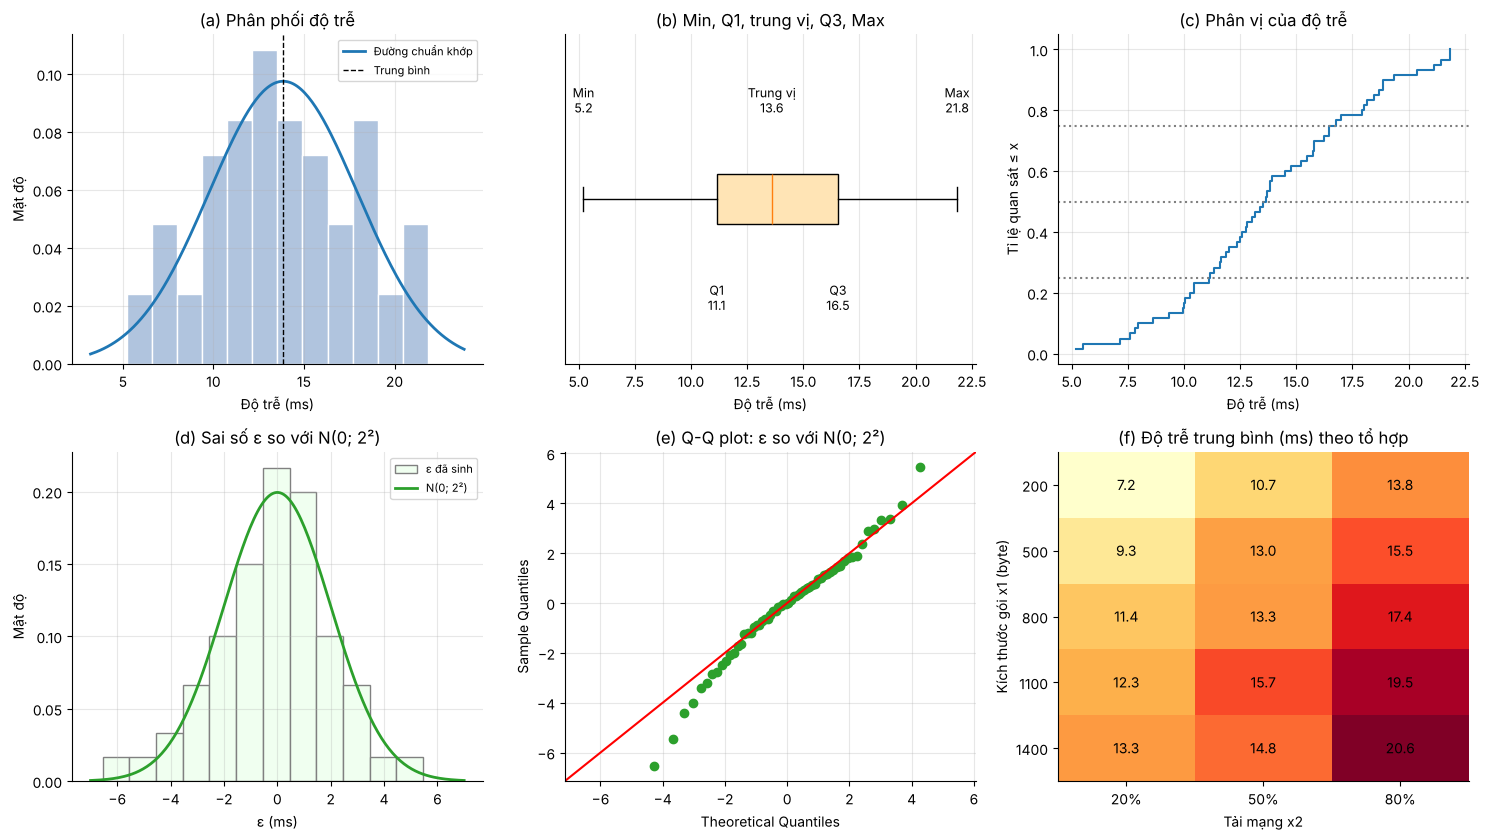

Sai số ε sinh ra: trung bình = -0.146 (kỳ vọng 0), độ lệch chuẩn = 2.243 (kỳ vọng 2), Shapiro-Wilk p = 0.631


In [6]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))

# (a) histogram độ trễ + đường chuẩn
ax[0, 0].hist(df["y"], bins=12, density=True, color="lightsteelblue", edgecolor="white")
xx = np.linspace(df["y"].min() - 2, df["y"].max() + 2, 200)
ax[0, 0].plot(xx, stats.norm.pdf(xx, df["y"].mean(), df["y"].std()), color="tab:blue", lw=2, label="Đường chuẩn khớp")
ax[0, 0].axvline(df["y"].mean(), color="black", ls="--", lw=1, label="Trung bình")
ax[0, 0].set(title="(a) Phân phối độ trễ", xlabel="Độ trễ (ms)", ylabel="Mật độ"); ax[0, 0].legend(fontsize=8)

# (b) boxplot với 5 số tóm tắt
q = np.percentile(df["y"], [0, 25, 50, 75, 100])
ax[0, 1].boxplot(df["y"], vert=False, whis=(0, 100), patch_artist=True, boxprops=dict(facecolor="moccasin"))
for val, ten, dy in zip(q, ["Min", "Q1", "Trung vị", "Q3", "Max"], [.3, -.3, .3, -.3, .3]):
    ax[0, 1].annotate(f"{ten}\n{val:.1f}", (val, 1), (val, 1 + dy), ha="center", va="center", fontsize=9)
ax[0, 1].set(title="(b) Min, Q1, trung vị, Q3, Max", xlabel="Độ trễ (ms)", yticks=[], ylim=(.5, 1.5)); ax[0, 1].grid(axis="y")

# (c) hàm phân phối thực nghiệm
ys = np.sort(df["y"]); ax[0, 2].step(ys, np.arange(1, len(ys) + 1) / len(ys), where="post")
for pr in (.25, .5, .75): ax[0, 2].axhline(pr, color="gray", ls=":")
ax[0, 2].set(title="(c) Phân vị của độ trễ", xlabel="Độ trễ (ms)", ylabel="Tỉ lệ quan sát ≤ x")

# (d) histogram sai số ε so với N(0; 2^2)
ax[1, 0].hist(eps, bins=12, density=True, color="honeydew", edgecolor="gray", label="ε đã sinh")
xe = np.linspace(-7, 7, 200); ax[1, 0].plot(xe, stats.norm.pdf(xe, 0, 2), color="tab:green", lw=2, label="N(0; 2²)")
ax[1, 0].set(title="(d) Sai số ε so với N(0; 2²)", xlabel="ε (ms)", ylabel="Mật độ"); ax[1, 0].legend(fontsize=8)

# (e) Q-Q plot của ε
sm.qqplot(eps, stats.norm, loc=0, scale=2, line="45", ax=ax[1, 1], markerfacecolor="tab:green", markeredgecolor="tab:green")
ax[1, 1].set_title("(e) Q-Q plot: ε so với N(0; 2²)")

# (f) heatmap trung bình độ trễ theo tổ hợp
tb = df.pivot_table(index="x1", columns="x2", values="y", aggfunc="mean")
im = ax[1, 2].imshow(tb.values, cmap="YlOrRd", aspect="auto")
ax[1, 2].set_xticks(range(3)); ax[1, 2].set_xticklabels([f"{c}%" for c in tb.columns])
ax[1, 2].set_yticks(range(5)); ax[1, 2].set_yticklabels(tb.index)
for i in range(5):
    for j in range(3): ax[1, 2].text(j, i, f"{tb.values[i, j]:.1f}", ha="center", va="center")
ax[1, 2].set(title="(f) Độ trễ trung bình (ms) theo tổ hợp", xlabel="Tải mạng x2", ylabel="Kích thước gói x1 (byte)"); ax[1, 2].grid(False)
plt.tight_layout(); plt.show()

print(f"Sai số ε sinh ra: trung bình = {eps.mean():.3f} (kỳ vọng 0), độ lệch chuẩn = {eps.std(ddof=1):.3f} (kỳ vọng 2), "
      f"Shapiro-Wilk p = {stats.shapiro(eps).pvalue:.3f}")

**Lập luận và kết luận cho Yêu cầu 1**
- Hình (a), (b), (c): độ trễ phân bố khá cân đối quanh trung bình, trung vị gần trung bình, không có điểm ngoại lai bất thường.
- Hình (d), (e): sai số bám sát đường chuẩn $N(0;2^2)$ và Shapiro–Wilk có $p > 0{,}05$, nên bộ sinh dữ liệu hoạt động đúng như đề yêu cầu.
- Hình (f): đi từ trái sang phải (tải tăng) và đi từ trên xuống dưới (gói lớn hơn) thì ô càng đậm, tức độ trễ lớn hơn. Đây là dấu hiệu đầu tiên cho thấy cả hai biến đều có ảnh hưởng.
- **Kết luận:** dữ liệu cân bằng, đạt yêu cầu, đủ điều kiện để chuyển sang bước hồi quy.

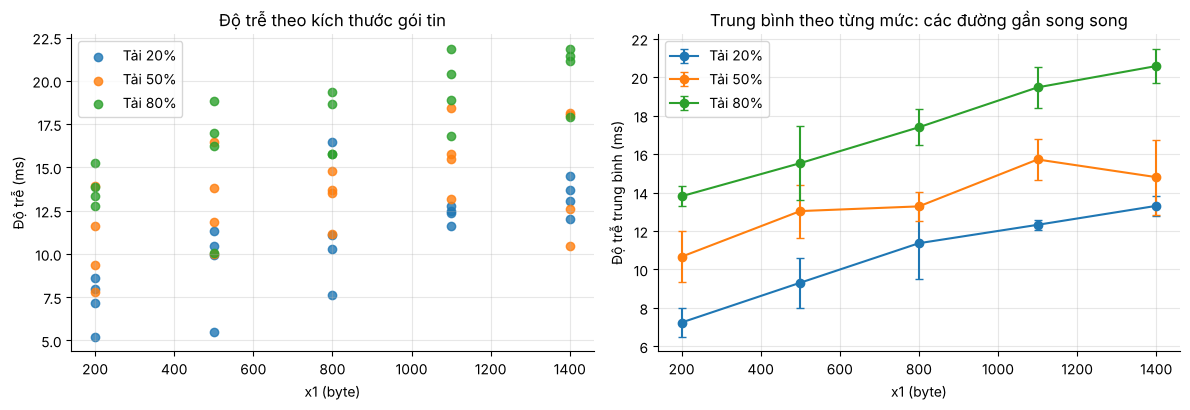

In [7]:
# Biểu đồ tương tác: nếu các đường gần song song thì tác động của x1 giống nhau ở mọi mức tải
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for m in x2_muc:
    s = df[df["x2"] == m]
    ax[0].scatter(s["x1"], s["y"], color=MAU[m], label=f"Tải {m}%", alpha=.8)
ax[0].set(title="Độ trễ theo kích thước gói tin", xlabel="x1 (byte)", ylabel="Độ trễ (ms)"); ax[0].legend()

for m in x2_muc:
    g = df[df["x2"] == m].groupby("x1")["y"]
    ax[1].errorbar(x1_muc, g.mean(), yerr=g.std() / 2, marker="o", capsize=3, color=MAU[m], label=f"Tải {m}%")
ax[1].set(title="Trung bình theo từng mức: các đường gần song song", xlabel="x1 (byte)", ylabel="Độ trễ trung bình (ms)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Nhận xét:** ba đường (ứng với ba mức tải) đi lên gần song song nhau và nằm tách tầng: tải càng cao thì đường càng cao. Hai điều này gợi ý (i) $x_1$ làm tăng độ trễ gần như tuyến tính, (ii) tải mạng cộng thêm một khoảng gần cố định, không làm thay đổi độ dốc theo $x_1$. Đây là cơ sở để chọn mô hình tuyến tính cộng tính ở các bước sau.

## Yêu cầu 2. Hồi quy đơn: chỉ dùng kích thước gói tin

**Mô hình:** $Y = \beta_0 + \beta_1 x_1 + \epsilon$.

**Vì sao chọn hồi quy tuyến tính đơn?** $Y$ là biến liên tục, $x_1$ là biến định lượng, và biểu đồ ở Yêu cầu 1 cho thấy xu hướng gần đường thẳng. Ta ước lượng bằng bình phương tối thiểu (chọn đường làm tổng bình phương phần dư nhỏ nhất):
$$\hat\beta_1 = \frac{S_{xy}}{S_{xx}},\qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x$$

In [8]:
mo_hinh_don = smf.ols("y ~ x1", data=df).fit()
print(mo_hinh_don.summary().tables[1])

# Kiểm tra lại bằng công thức tay
x, y = df["x1"], df["y"]
b1_tay = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0_tay = y.mean() - b1_tay * x.mean()
print(f"\nCông thức tay: b0 = {b0_tay:.4f}, b1 = {b1_tay:.6f}  (trùng với bảng trên)")
print(f"R2 = {mo_hinh_don.rsquared:.4f} | R2 hiệu chỉnh = {mo_hinh_don.rsquared_adj:.4f} | s = {mo_hinh_don.mse_resid**0.5:.3f} ms")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.9780      0.981     10.175      0.000       8.015      11.941
x1             0.0048      0.001      4.474      0.000       0.003       0.007

Công thức tay: b0 = 9.9780, b1 = 0.004845  (trùng với bảng trên)
R2 = 0.2565 | R2 hiệu chỉnh = 0.2437 | s = 3.559 ms


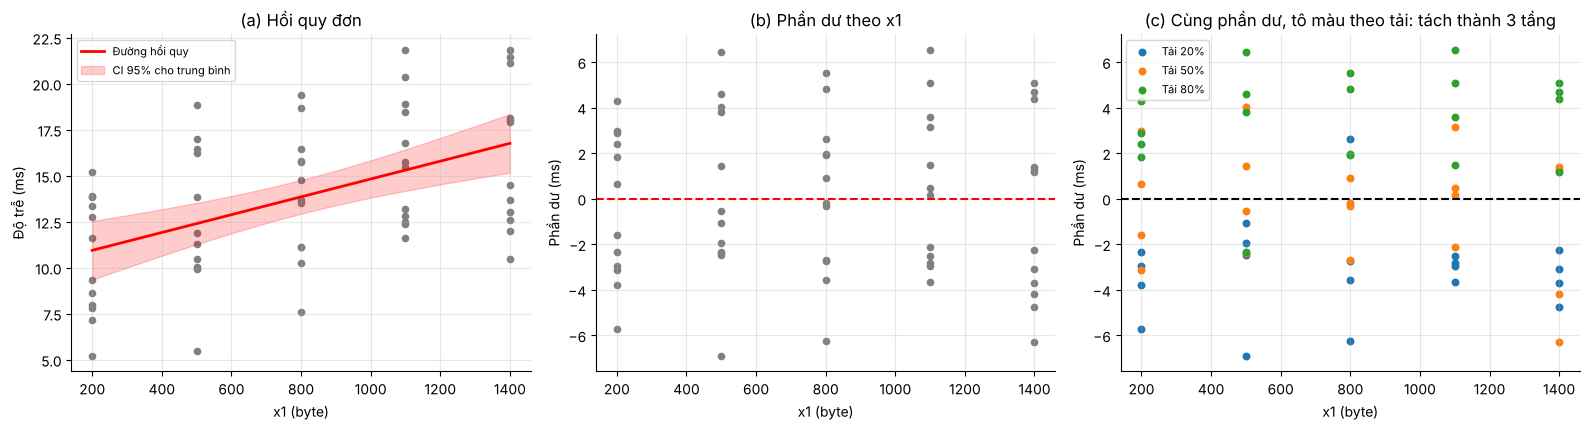

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

# (a) đường hồi quy + khoảng tin cậy
xs = pd.DataFrame({"x1": np.linspace(200, 1400, 100)})
pr = mo_hinh_don.get_prediction(xs).summary_frame(0.05)
ax[0].scatter(df["x1"], df["y"], color="gray", s=20)
ax[0].plot(xs["x1"], pr["mean"], color="red", lw=2, label="Đường hồi quy")
ax[0].fill_between(xs["x1"], pr["mean_ci_lower"], pr["mean_ci_upper"], color="red", alpha=.2, label="CI 95% cho trung bình")
ax[0].set(title="(a) Hồi quy đơn", xlabel="x1 (byte)", ylabel="Độ trễ (ms)"); ax[0].legend(fontsize=8)

# (b) phần dư theo x1
ax[1].scatter(df["x1"], mo_hinh_don.resid, color="gray", s=20); ax[1].axhline(0, color="red", ls="--")
ax[1].set(title="(b) Phần dư theo x1", xlabel="x1 (byte)", ylabel="Phần dư (ms)")

# (c) phần dư theo x1, tô màu theo tải: nếu có 3 tầng nghĩa là mô hình bỏ sót tải mạng
for m in x2_muc:
    s = df[df["x2"] == m]
    ax[2].scatter(s["x1"], mo_hinh_don.resid[s.index], color=MAU[m], s=22, label=f"Tải {m}%")
ax[2].axhline(0, color="black", ls="--")
ax[2].set(title="(c) Cùng phần dư, tô màu theo tải: tách thành 3 tầng", xlabel="x1 (byte)", ylabel="Phần dư (ms)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [10]:
b1d, r2d = mo_hinh_don.params["x1"], mo_hinh_don.rsquared
print(f"Kết luận số liệu: tăng 100 byte thì độ trễ trung bình tăng {100*b1d:.2f} ms (p = {mo_hinh_don.pvalues['x1']:.1e}).")
print(f"Mô hình chỉ giải thích được {100*r2d:.1f}% biến thiên của độ trễ, còn {100*(1-r2d):.1f}% chưa giải thích được.")

Kết luận số liệu: tăng 100 byte thì độ trễ trung bình tăng 0.48 ms (p = 3.6e-05).
Mô hình chỉ giải thích được 25.7% biến thiên của độ trễ, còn 74.3% chưa giải thích được.


**Lập luận và kết luận cho Yêu cầu 2**
- Hình (a): đường thẳng đi đúng xu hướng chung và độ dốc dương, nên kích thước gói tin có ảnh hưởng đến độ trễ.
- Nhưng các điểm rải khá rộng quanh đường thẳng, $R^2$ thấp. Chỉ dùng $x_1$ thì còn nhiều biến thiên chưa giải thích được.
- Hình (c) là điểm mấu chốt: cùng một phần dư nhưng khi tô màu theo tải thì **tách thành ba tầng** (tải 20% nằm dưới 0, tải 80% nằm trên 0). Nếu mô hình đã đủ biến thì phần dư phải trộn lẫn ngẫu nhiên, không tách tầng theo một biến nào. Như vậy phần "chưa giải thích" không phải nhiễu thuần túy, nó chứa ảnh hưởng của tải mạng mà mô hình đơn đã bỏ sót.
- **Kết luận:** mô hình đơn đúng hướng nhưng chưa đủ, cần thêm $x_2$.

## Yêu cầu 3. Hồi quy bội: dùng cả hai biến

**Mô hình:** $Y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \epsilon$.

**Điều kiện áp dụng:** quan hệ tuyến tính, sai số độc lập, sai số xấp xỉ chuẩn, phương sai sai số không đổi, và hai biến dự báo không phụ thuộc tuyến tính chặt vào nhau. Thiết kế ở Yêu cầu 1 đảm bảo điều kiện cuối ($\text{corr}=0$); các điều kiện còn lại nhóm kiểm tra ở Yêu cầu 7.

In [11]:
mo_hinh_boi = smf.ols("y ~ x1 + x2", data=df).fit()
print(mo_hinh_boi.summary().tables[1])
print(f"R2 = {mo_hinh_boi.rsquared:.4f} | R2 hiệu chỉnh = {mo_hinh_boi.rsquared_adj:.4f} | s = {mo_hinh_boi.mse_resid**0.5:.3f} ms")

# Kiểm tra lại bằng công thức ma trận (X'X)^-1 X'y
X = np.column_stack([np.ones(len(df)), df["x1"], df["x2"]])
beta_tay = np.linalg.inv(X.T @ X) @ X.T @ df["y"].to_numpy()
print("Công thức ma trận:", beta_tay.round(5), "(trùng với bảng trên)")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.4362      0.864      5.137      0.000       2.707       6.165
x1             0.0048      0.001      7.030      0.000       0.003       0.006
x2             0.1108      0.012      9.285      0.000       0.087       0.135
R2 = 0.7041 | R2 hiệu chỉnh = 0.6937 | s = 2.265 ms
Công thức ma trận: [4.43622 0.00484 0.11083] (trùng với bảng trên)


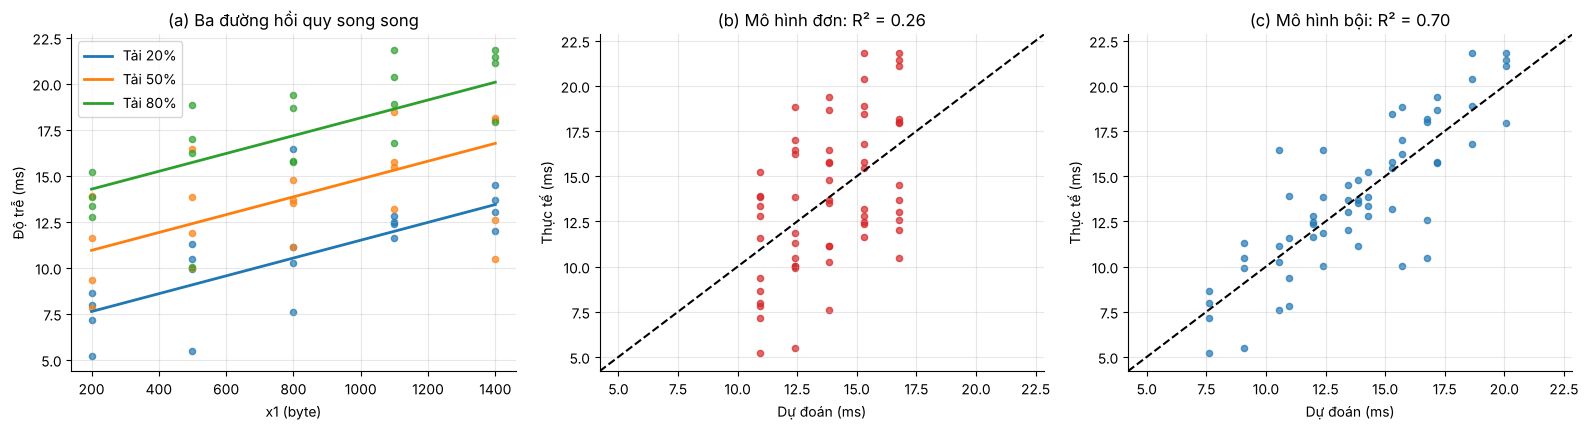

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

# (a) ba đường hồi quy ứng với ba mức tải
xs = np.linspace(200, 1400, 50)
for m in x2_muc:
    s = df[df["x2"] == m]
    ax[0].scatter(s["x1"], s["y"], color=MAU[m], s=20, alpha=.7)
    ax[0].plot(xs, mo_hinh_boi.predict(pd.DataFrame({"x1": xs, "x2": m})), color=MAU[m], lw=2, label=f"Tải {m}%")
ax[0].set(title="(a) Ba đường hồi quy song song", xlabel="x1 (byte)", ylabel="Độ trễ (ms)"); ax[0].legend()

# (b) thực tế vs dự đoán: mô hình đơn
lim = [df["y"].min() - 1, df["y"].max() + 1]
ax[1].scatter(mo_hinh_don.fittedvalues, df["y"], s=20, color="tab:red", alpha=.7)
ax[1].plot(lim, lim, "k--"); ax[1].set(title=f"(b) Mô hình đơn: R² = {mo_hinh_don.rsquared:.2f}", xlabel="Dự đoán (ms)", ylabel="Thực tế (ms)", xlim=lim, ylim=lim)

# (c) thực tế vs dự đoán: mô hình bội
ax[2].scatter(mo_hinh_boi.fittedvalues, df["y"], s=20, color="tab:blue", alpha=.7)
ax[2].plot(lim, lim, "k--"); ax[2].set(title=f"(c) Mô hình bội: R² = {mo_hinh_boi.rsquared:.2f}", xlabel="Dự đoán (ms)", ylabel="Thực tế (ms)", xlim=lim, ylim=lim)
plt.tight_layout(); plt.show()

**Lập luận và kết luận cho Yêu cầu 3**
- Hình (a): mô hình bội cho **ba đường song song**, mỗi đường là một mức tải. Đường cao hơn ứng với tải cao hơn, khớp với dữ liệu cả ba nhóm màu.
- Hình (b) và (c): trục ngang là giá trị mô hình dự đoán, trục dọc là giá trị thực. Điểm càng sát đường chéo đứt nét thì dự đoán càng tốt. Mô hình đơn có các điểm tản rất rộng, mô hình bội gom sát đường chéo hơn nhiều.
- **Kết luận:** thêm tải mạng vào mô hình làm dự đoán tốt lên rõ rệt; lượng cải thiện sẽ được kiểm định bằng số ở Yêu cầu 5.

## Yêu cầu 4. Giải thích từng hệ số

Cụm **"giữ biến còn lại không đổi"** nghĩa là: ta so sánh hai trường hợp **có cùng giá trị của biến kia**, khi đó hệ số cho biết độ trễ trung bình thay đổi bao nhiêu nếu biến này tăng 1 đơn vị. Đây là chỗ khác nhau giữa hồi quy bội và hồi quy đơn: hồi quy đơn trộn lẫn mọi thứ, hồi quy bội tách riêng tác động của từng biến.

In [13]:
b0, b1, b2 = mo_hinh_boi.params
ci = mo_hinh_boi.conf_int(0.05)

print(f"b1 = {b1:.5f}: tăng 100 byte thì độ trễ TB tăng {100*b1:.2f} ms  (CI 95%: {100*ci.loc['x1',0]:.2f} đến {100*ci.loc['x1',1]:.2f}), giữ tải mạng không đổi")
print(f"b2 = {b2:.4f}: tăng 10% tải thì độ trễ TB tăng {10*b2:.2f} ms  (CI 95%: {10*ci.loc['x2',0]:.2f} đến {10*ci.loc['x2',1]:.2f}), giữ kích thước gói không đổi")
print(f"b0 = {b0:.3f}: độ trễ TB khi x1 = 0 và x2 = 0, nằm ngoài vùng dữ liệu nên không có ý nghĩa thực tế")

# Chứng minh bằng "thí nghiệm" trên mô hình đã ước lượng
P = lambda a, b: float(mo_hinh_boi.predict(pd.DataFrame({"x1": [a], "x2": [b]})).iloc[0])
print(f"\nGiữ tải 50%, gói từ 800 lên 900 byte: độ trễ tăng {P(900,50)-P(800,50):.3f} ms (= 100*b1)")
print(f"Giữ gói 800 byte, tải từ 50% lên 60% : độ trễ tăng {P(800,60)-P(800,50):.3f} ms (= 10*b2)")

b1 = 0.00484: tăng 100 byte thì độ trễ TB tăng 0.48 ms  (CI 95%: 0.35 đến 0.62), giữ tải mạng không đổi
b2 = 0.1108: tăng 10% tải thì độ trễ TB tăng 1.11 ms  (CI 95%: 0.87 đến 1.35), giữ kích thước gói không đổi
b0 = 4.436: độ trễ TB khi x1 = 0 và x2 = 0, nằm ngoài vùng dữ liệu nên không có ý nghĩa thực tế

Giữ tải 50%, gói từ 800 lên 900 byte: độ trễ tăng 0.484 ms (= 100*b1)
Giữ gói 800 byte, tải từ 50% lên 60% : độ trễ tăng 1.108 ms (= 10*b2)


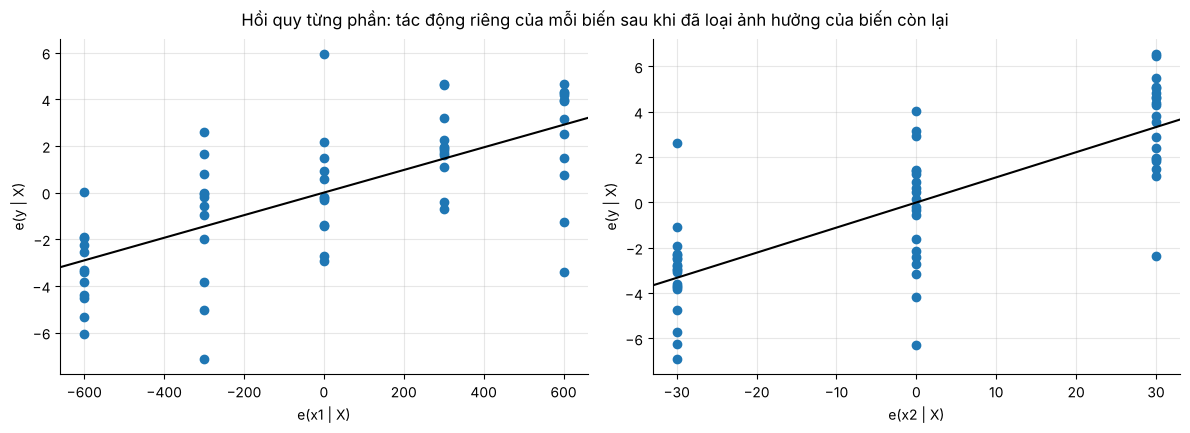

In [14]:
fig = plt.figure(figsize=(12, 4.2))
sm.graphics.plot_partregress_grid(mo_hinh_boi, exog_idx=["x1", "x2"], grid=(1, 2), fig=fig)
fig.suptitle("Hồi quy từng phần: tác động riêng của mỗi biến sau khi đã loại ảnh hưởng của biến còn lại", y=1.02)
plt.show()

Hình trên chính là "giữ biến còn lại không đổi" được vẽ ra: mỗi ô vẽ phần của $Y$ còn lại sau khi trừ ảnh hưởng của biến kia, theo phần của biến này còn lại sau khi trừ ảnh hưởng của biến kia. Độ dốc của đường trong từng ô bằng đúng $\hat\beta_1$ và $\hat\beta_2$ của mô hình bội.

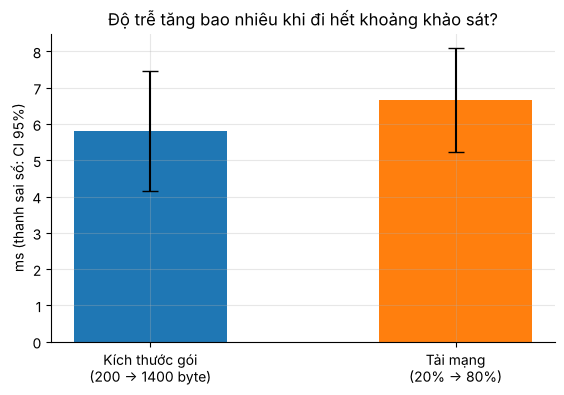

x1    5.81
x2    6.65


In [15]:
# Mỗi yếu tố làm độ trễ tăng bao nhiêu khi đi hết khoảng khảo sát?
khoang = {"x1": 1400 - 200, "x2": 80 - 20}
tac_dong = pd.Series({k: mo_hinh_boi.params[k] * khoang[k] for k in khoang})
can = pd.DataFrame({k: ci.loc[k] * khoang[k] for k in khoang}).T

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(["Kích thước gói\n(200 → 1400 byte)", "Tải mạng\n(20% → 80%)"], tac_dong.values, color=["tab:blue", "tab:orange"], width=.5,
       yerr=[tac_dong.values - can[0].values, can[1].values - tac_dong.values], capsize=6)
ax.set(title="Độ trễ tăng bao nhiêu khi đi hết khoảng khảo sát?", ylabel="ms (thanh sai số: CI 95%)")
plt.show()
print(tac_dong.round(2).to_string())

**Lập luận và kết luận cho Yêu cầu 4**
- $\hat\beta_1$ dương: gói tin càng lớn thì thời gian truyền và xử lý càng dài, độ trễ tăng. Cứ 100 byte thêm vào làm độ trễ tăng thêm khoảng $100\hat\beta_1$ ms (khi tải không đổi).
- $\hat\beta_2$ dương: tải mạng càng cao thì hàng đợi càng dài, độ trễ tăng. Cứ 10 điểm phần trăm tải thêm làm độ trễ tăng khoảng $10\hat\beta_2$ ms (khi kích thước gói không đổi).
- $\hat\beta_0$ chỉ là hằng số của đường thẳng: không ai đo được gói 0 byte ở tải 0%, nên không diễn giải thực tế.
- Biểu đồ cột cho thấy hai yếu tố có tác động ở **cùng cỡ độ lớn** khi đi hết khoảng khảo sát. Vì vậy không thể bỏ qua yếu tố nào.
- **Kết luận:** hệ số cho nhóm vận hành biết mỗi yếu tố đóng góp bao nhiêu ms, đúng với câu hỏi đặt ra ở đầu bài.

## Yêu cầu 5. Kiểm định hệ số, so sánh $R^2$ hiệu chỉnh và phần dư

### 5.1 Kiểm định t cho từng hệ số
$H_0: \beta_j = 0$ (biến $x_j$ không ảnh hưởng) và $H_1: \beta_j \ne 0$. Thống kê $t = \hat\beta_j / SE(\hat\beta_j)$. Nếu $p < 0{,}05$ thì bác bỏ $H_0$.

,Hệ số,Sai số chuẩn,t,p-value,Kết luận (5%)
Intercept,4.43622,0.86352,5.13734,3.53e-06,Bác bỏ H0: có ý nghĩa
x1,0.00484,0.00069,7.02961,2.84e-09,Bác bỏ H0: có ý nghĩa
x2,0.11083,0.01194,9.28519,5.30e-13,Bác bỏ H0: có ý nghĩa


Kiểm định F toàn mô hình (H0: b1 = b2 = 0): F = 67.82, p = 8.5e-16


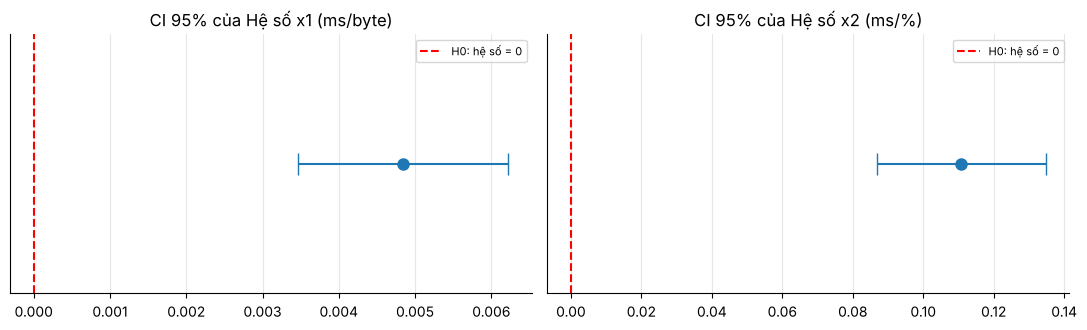

In [16]:
bang = pd.DataFrame({"Hệ số": mo_hinh_boi.params, "Sai số chuẩn": mo_hinh_boi.bse, "t": mo_hinh_boi.tvalues}).round(5)
bang["p-value"] = [f"{p:.2e}" for p in mo_hinh_boi.pvalues]          # hiện dạng khoa học để không bị làm tròn thành 0
bang["Kết luận (5%)"] = np.where(mo_hinh_boi.pvalues < 0.05, "Bác bỏ H0: có ý nghĩa", "Không bác bỏ H0")
display(bang)
print(f"Kiểm định F toàn mô hình (H0: b1 = b2 = 0): F = {mo_hinh_boi.fvalue:.2f}, p = {mo_hinh_boi.f_pvalue:.1e}")

# Biểu đồ khoảng tin cậy: nếu khoảng không chứa 0 thì bác bỏ H0 ở mức 5%
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, ten, he, k in [(ax[0], "Hệ số x1 (ms/byte)", "x1", 0), (ax[1], "Hệ số x2 (ms/%)", "x2", 1)]:
    h = mo_hinh_boi.params[he]; lo, hi = ci.loc[he]
    a.errorbar([h], [0], xerr=[[h - lo], [hi - h]], fmt="o", capsize=8, color="tab:blue", ms=8)
    a.axvline(0, color="red", ls="--", label="H0: hệ số = 0")
    a.set(title=f"CI 95% của {ten}", yticks=[]); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Đọc kết quả:** cả hai khoảng tin cậy đều nằm hẳn về một phía của 0 và cả hai $p < 0{,}05$. Vậy bác bỏ $H_0$ với cả $\beta_1$ và $\beta_2$: kích thước gói tin và tải mạng đều có ảnh hưởng có ý nghĩa thống kê đến độ trễ.

### 5.2 So sánh hai mô hình
- $R^2 = 1 - SSE/SST$ luôn tăng khi thêm biến (kể cả biến vô dụng), nên không công bằng.
- $R^2$ hiệu chỉnh $= 1 - \dfrac{SSE/(n-p)}{SST/(n-1)}$ có phạt việc thêm biến; nếu thêm biến mà nó tăng thì biến đó đáng giữ.
- Kiểm định F từng phần hỏi: thêm $x_2$ có làm SSE giảm đáng kể không? ($H_0$: $\beta_2 = 0$).

,R2,R2 hiệu chỉnh,SSE,s (ms)
Mô hình đơn (x1),0.257,0.244,734.618,3.559
"Mô hình bội (x1, x2)",0.704,0.694,292.380,2.265


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,58.0,734.6178,0.0,NaN,NaN,NaN
1,57.0,292.3804,1.0,442.2373,86.2148,0.0


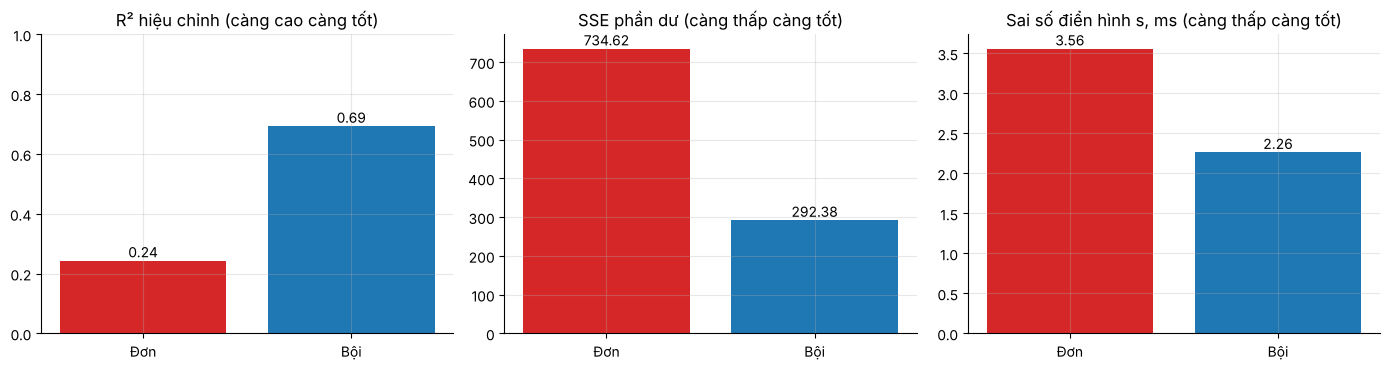

In [17]:
so_sanh = pd.DataFrame({
    "R2": [mo_hinh_don.rsquared, mo_hinh_boi.rsquared],
    "R2 hiệu chỉnh": [mo_hinh_don.rsquared_adj, mo_hinh_boi.rsquared_adj],
    "SSE": [mo_hinh_don.ssr, mo_hinh_boi.ssr],
    "s (ms)": [mo_hinh_don.mse_resid ** 0.5, mo_hinh_boi.mse_resid ** 0.5],
}, index=["Mô hình đơn (x1)", "Mô hình bội (x1, x2)"])
display(so_sanh.round(3))

an = anova_lm(mo_hinh_don, mo_hinh_boi)
display(an.round(4))
F, pF = an.loc[1, "F"], an.loc[1, "Pr(>F)"]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ten = ["Đơn", "Bội"]; mau = ["tab:red", "tab:blue"]
ax[0].bar(ten, so_sanh["R2 hiệu chỉnh"], color=mau); ax[0].set(title="R² hiệu chỉnh (càng cao càng tốt)", ylim=(0, 1))
ax[1].bar(ten, so_sanh["SSE"], color=mau); ax[1].set(title="SSE phần dư (càng thấp càng tốt)")
ax[2].bar(ten, so_sanh["s (ms)"], color=mau); ax[2].set(title="Sai số điển hình s, ms (càng thấp càng tốt)")
for a, col in zip(ax, ["R2 hiệu chỉnh", "SSE", "s (ms)"]):
    for i, v in enumerate(so_sanh[col]): a.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

### 5.3 So sánh phần dư của hai mô hình
Mô hình tốt thì phần dư chỉ là nhiễu ngẫu nhiên: quanh 0, và không phụ thuộc vào biến nào. Ta vẽ phần dư theo từng mức tải cho cả hai mô hình, và dùng kiểm định **Kruskal–Wallis** (phi tham số, Chương 7) để hỏi: phần dư ở 3 mức tải có cùng vị trí không? ($H_0$: cùng vị trí.) Mô hình tốt thì **không** bác bỏ $H_0$.

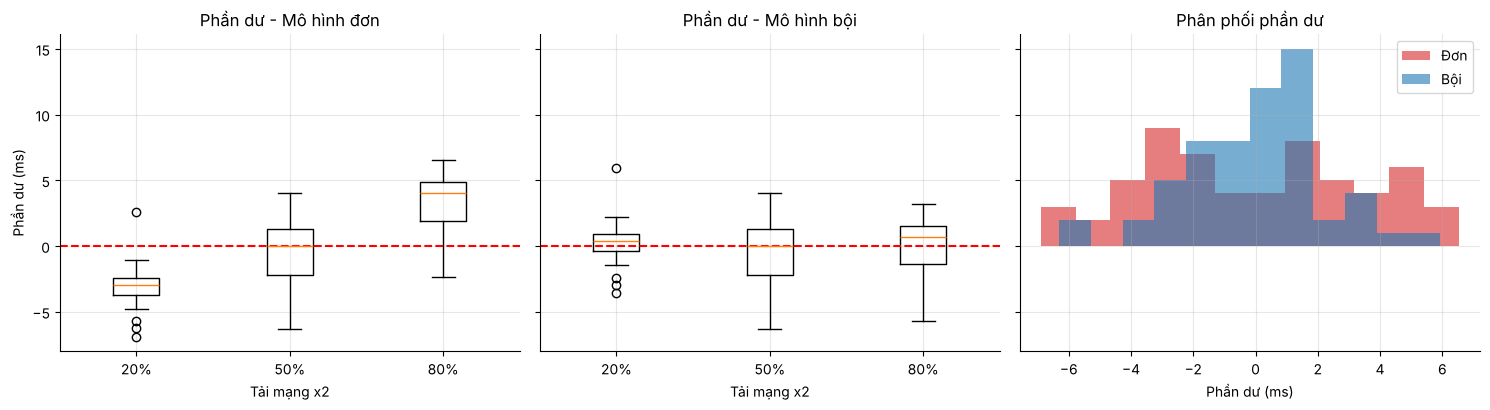

Kruskal-Wallis phần dư mô hình đơn: H = 36.30, p = 1.3e-08
Kruskal-Wallis phần dư mô hình bội: H = 0.85, p = 0.654


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for a, mh, ten in [(ax[0], mo_hinh_don, "Mô hình đơn"), (ax[1], mo_hinh_boi, "Mô hình bội")]:
    a.boxplot([mh.resid[df["x2"] == m] for m in x2_muc]); a.set_xticklabels([f"{m}%" for m in x2_muc])
    a.axhline(0, color="red", ls="--"); a.set(title=f"Phần dư - {ten}", xlabel="Tải mạng x2")
ax[0].set_ylabel("Phần dư (ms)")
ax[2].hist(mo_hinh_don.resid, bins=12, alpha=.6, color="tab:red", label="Đơn")
ax[2].hist(mo_hinh_boi.resid, bins=12, alpha=.6, color="tab:blue", label="Bội")
ax[2].set(title="Phân phối phần dư", xlabel="Phần dư (ms)"); ax[2].legend()
plt.tight_layout(); plt.show()

kw_don = stats.kruskal(*[mo_hinh_don.resid[df["x2"] == m] for m in x2_muc])
kw_boi = stats.kruskal(*[mo_hinh_boi.resid[df["x2"] == m] for m in x2_muc])
print(f"Kruskal-Wallis phần dư mô hình đơn: H = {kw_don.statistic:.2f}, p = {kw_don.pvalue:.1e}")
print(f"Kruskal-Wallis phần dư mô hình bội: H = {kw_boi.statistic:.2f}, p = {kw_boi.pvalue:.3f}")

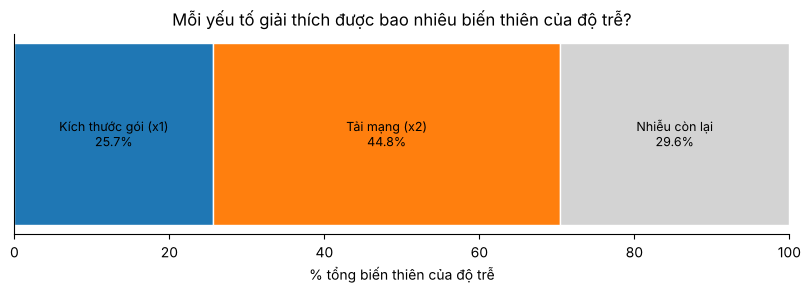

In [19]:
# Chia nhỏ tổng biến thiên SST của độ trễ: bao nhiêu % do x1, do x2, do nhiễu
m_x2 = smf.ols("y ~ x2", data=df).fit()
SST = mo_hinh_don.ssr + mo_hinh_don.ess
phan = pd.Series({"Kích thước gói (x1)": mo_hinh_don.ess / SST, "Tải mạng (x2)": m_x2.ess / SST, "Nhiễu còn lại": mo_hinh_boi.ssr / SST})

fig, ax = plt.subplots(figsize=(10, 2.6)); trai = 0
for (ten, v), mau in zip(phan.items(), ["tab:blue", "tab:orange", "lightgray"]):
    ax.barh([0], [100 * v], left=trai, color=mau, edgecolor="white"); ax.text(trai + 50 * v, 0, f"{ten}\n{100*v:.1f}%", ha="center", va="center", fontsize=9); trai += 100 * v
ax.set(xlim=(0, 100), yticks=[], xlabel="% tổng biến thiên của độ trễ", title="Mỗi yếu tố giải thích được bao nhiêu biến thiên của độ trễ?"); ax.grid(False)
plt.show()

In [20]:
print("KẾT LUẬN YÊU CẦU 5 (số liệu của lần chạy này)")
print(f"1) Cả hai hệ số có p < 0,05 (x1: {mo_hinh_boi.pvalues['x1']:.1e}; x2: {mo_hinh_boi.pvalues['x2']:.1e}) -> cả hai ảnh hưởng có ý nghĩa.")
print(f"2) R2 hiệu chỉnh tăng từ {mo_hinh_don.rsquared_adj:.3f} (đơn) lên {mo_hinh_boi.rsquared_adj:.3f} (bội); SSE giảm {100*(1-mo_hinh_boi.ssr/mo_hinh_don.ssr):.0f}%; "
      f"sai số điển hình giảm từ {mo_hinh_don.mse_resid**0.5:.2f} xuống {mo_hinh_boi.mse_resid**0.5:.2f} ms.")
print(f"3) Kiểm định F từng phần: F = {F:.1f}, p = {pF:.1e} -> thêm tải mạng làm giảm phần dư có ý nghĩa.")
print(f"4) Phần dư mô hình đơn khác nhau giữa các mức tải (p = {kw_don.pvalue:.1e}), mô hình bội thì không (p = {kw_boi.pvalue:.2f}) -> mô hình bội đã giải thích hết phần có hệ thống.")

KẾT LUẬN YÊU CẦU 5 (số liệu của lần chạy này)
1) Cả hai hệ số có p < 0,05 (x1: 2.8e-09; x2: 5.3e-13) -> cả hai ảnh hưởng có ý nghĩa.
2) R2 hiệu chỉnh tăng từ 0.244 (đơn) lên 0.694 (bội); SSE giảm 60%; sai số điển hình giảm từ 3.56 xuống 2.26 ms.
3) Kiểm định F từng phần: F = 86.2, p = 5.3e-13 -> thêm tải mạng làm giảm phần dư có ý nghĩa.
4) Phần dư mô hình đơn khác nhau giữa các mức tải (p = 1.3e-08), mô hình bội thì không (p = 0.65) -> mô hình bội đã giải thích hết phần có hệ thống.


**Lập luận và kết luận cho Yêu cầu 5**
1. **Hệ số có ý nghĩa:** khoảng tin cậy không chứa 0 và $p<0{,}05$, nên cả hai biến đều ảnh hưởng thật, không phải do may rủi mẫu.
2. **Mô hình bội tốt hơn:** $R^2$ hiệu chỉnh tăng mạnh, SSE và $s$ giảm mạnh (ba biểu đồ cột cùng một kết luận). Vì $R^2$ hiệu chỉnh đã phạt việc thêm biến mà vẫn tăng, nên $x_2$ thật sự đáng giữ, không phải chỉ "tăng do thêm biến".
3. **Phần dư:** ở mô hình đơn, phần dư tăng dần theo tải (hộp tải 20% nằm dưới 0, tải 80% nằm trên 0) và Kruskal–Wallis bác bỏ $H_0$: mô hình bỏ sót tải mạng. Ở mô hình bội, ba hộp cùng quanh 0 và không bác bỏ $H_0$: phần dư đã là nhiễu ngẫu nhiên.
4. **Biểu đồ chia biến thiên:** cả kích thước gói và tải mạng đều giải thích một phần đáng kể biến thiên của độ trễ (tỉ lệ cụ thể ghi trên biểu đồ, tải mạng giải thích nhiều hơn); phần còn lại là nhiễu không dự đoán được.
- **Kết luận:** nên dùng mô hình bội. Dùng mô hình đơn là bỏ sót gần một nửa biến thiên của độ trễ.

## Yêu cầu 6. Dự đoán độ trễ khi $x_1 = 1000$ byte và $x_2 = 60\%$

Ta tính ba thứ:
- **Giá trị dự đoán** $\hat y_0 = \hat\beta_0 + \hat\beta_1\cdot 1000 + \hat\beta_2\cdot 60$.
- **Khoảng tin cậy 95% cho độ trễ trung bình** của mọi gói có cùng điều kiện.
- **Khoảng dự đoán 95% cho một gói cụ thể** sắp gửi. Khoảng này rộng hơn vì ngoài sai số ước lượng đường thẳng còn có nhiễu ngẫu nhiên $\sigma^2$ của chính gói tin đó.

In [21]:
moi = pd.DataFrame({"x1": [1000], "x2": [60]})
kq = mo_hinh_boi.get_prediction(moi).summary_frame(alpha=0.05)
y0 = kq["mean"].iloc[0]
ci_lo, ci_hi = kq["mean_ci_lower"].iloc[0], kq["mean_ci_upper"].iloc[0]
pi_lo, pi_hi = kq["obs_ci_lower"].iloc[0], kq["obs_ci_upper"].iloc[0]

print(f"Độ trễ dự đoán: {y0:.2f} ms")
print(f"Khoảng tin cậy 95% cho độ trễ trung bình: [{ci_lo:.2f} ; {ci_hi:.2f}] ms (rộng {ci_hi-ci_lo:.2f})")
print(f"Khoảng dự đoán 95% cho một gói mới       : [{pi_lo:.2f} ; {pi_hi:.2f}] ms (rộng {pi_hi-pi_lo:.2f})")

# So sánh với mô hình đơn (không biết tải mạng)
kd = mo_hinh_don.get_prediction(moi).summary_frame(alpha=0.05)
print(f"\nNếu chỉ dùng mô hình đơn: dự đoán {kd['mean'].iloc[0]:.2f} ms, khoảng dự đoán [{kd['obs_ci_lower'].iloc[0]:.2f} ; {kd['obs_ci_upper'].iloc[0]:.2f}] (rộng {kd['obs_ci_upper'].iloc[0]-kd['obs_ci_lower'].iloc[0]:.2f})")

Độ trễ dự đoán: 15.93 ms
Khoảng tin cậy 95% cho độ trễ trung bình: [15.24 ; 16.62] ms (rộng 1.38)
Khoảng dự đoán 95% cho một gói mới       : [11.34 ; 20.52] ms (rộng 9.17)

Nếu chỉ dùng mô hình đơn: dự đoán 14.82 ms, khoảng dự đoán [7.63 ; 22.02] (rộng 14.39)


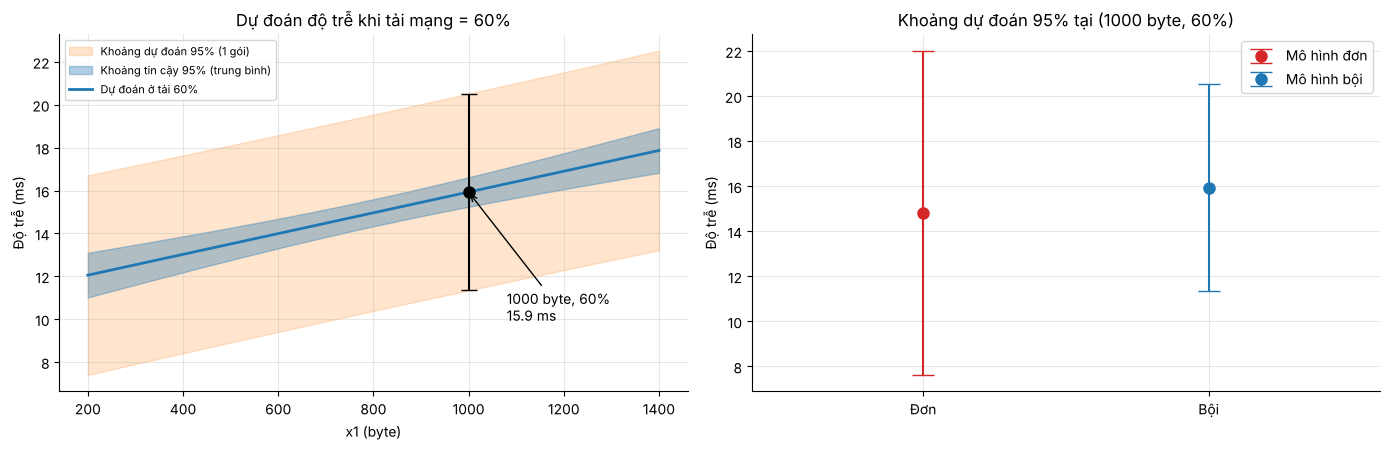

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
xs = pd.DataFrame({"x1": np.linspace(200, 1400, 100), "x2": 60})
g = mo_hinh_boi.get_prediction(xs).summary_frame(0.05)
ax[0].fill_between(xs["x1"], g["obs_ci_lower"], g["obs_ci_upper"], color="tab:orange", alpha=.2, label="Khoảng dự đoán 95% (1 gói)")
ax[0].fill_between(xs["x1"], g["mean_ci_lower"], g["mean_ci_upper"], color="tab:blue", alpha=.35, label="Khoảng tin cậy 95% (trung bình)")
ax[0].plot(xs["x1"], g["mean"], color="tab:blue", lw=2, label="Dự đoán ở tải 60%")
ax[0].errorbar([1000], [y0], yerr=[[y0 - pi_lo], [pi_hi - y0]], fmt="o", color="black", capsize=6, ms=8, zorder=5)
ax[0].annotate(f"1000 byte, 60%\n{y0:.1f} ms", (1000, y0), (1080, y0 - 6), arrowprops=dict(arrowstyle="->"))
ax[0].set(title="Dự đoán độ trễ khi tải mạng = 60%", xlabel="x1 (byte)", ylabel="Độ trễ (ms)"); ax[0].legend(fontsize=8, loc="upper left")

# So sánh khoảng dự đoán của hai mô hình tại điểm cần dự đoán
ax[1].errorbar([0], [kd["mean"].iloc[0]], yerr=[[kd["mean"].iloc[0] - kd["obs_ci_lower"].iloc[0]], [kd["obs_ci_upper"].iloc[0] - kd["mean"].iloc[0]]], fmt="o", color="tab:red", capsize=8, ms=8, label="Mô hình đơn")
ax[1].errorbar([1], [y0], yerr=[[y0 - pi_lo], [pi_hi - y0]], fmt="o", color="tab:blue", capsize=8, ms=8, label="Mô hình bội")
ax[1].set(title="Khoảng dự đoán 95% tại (1000 byte, 60%)", xticks=[0, 1], xticklabels=["Đơn", "Bội"], xlim=(-.6, 1.6), ylabel="Độ trễ (ms)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lập luận và kết luận cho Yêu cầu 6**
- Điểm (1000 byte, 60%) **không** nằm trong 15 tổ hợp đã đo nhưng nằm **bên trong** khoảng 200–1400 byte và 20–80%, nên đây là *nội suy* (đáng tin), khác với *ngoại suy* (ra ngoài khoảng dữ liệu).
- Dự đoán điểm cho biết giá trị hợp lý nhất. **Khoảng tin cậy** hẹp vì nó chỉ nói về độ trễ *trung bình*; **khoảng dự đoán** rộng hơn nhiều vì một gói cụ thể còn chịu nhiễu ngẫu nhiên. Hai khoảng trả lời hai câu hỏi khác nhau nên không được nhầm.
- Biểu đồ bên phải: khoảng dự đoán của mô hình bội **hẹp hơn** mô hình đơn tại cùng điểm, vì mô hình bội biết tải đang là 60% còn mô hình đơn thì không.
- **Kết luận:** xem ô tổng kết ngay bên dưới.

In [23]:
print("KẾT LUẬN YÊU CẦU 6")
print(f"Với gói 1000 byte ở tải 60%, độ trễ trung bình dự đoán là {y0:.1f} ms (tin cậy 95%: từ {ci_lo:.1f} đến {ci_hi:.1f} ms).")
print(f"Với một gói cụ thể, độ trễ có thể rơi vào khoảng {pi_lo:.1f} đến {pi_hi:.1f} ms với độ tin cậy 95%.")

KẾT LUẬN YÊU CẦU 6
Với gói 1000 byte ở tải 60%, độ trễ trung bình dự đoán là 15.9 ms (tin cậy 95%: từ 15.2 đến 16.6 ms).
Với một gói cụ thể, độ trễ có thể rơi vào khoảng 11.3 đến 20.5 ms với độ tin cậy 95%.


## Yêu cầu 7. Yếu tố thực tế chưa được mô hình xét đến và giới hạn khi áp dụng

### 7.1 Kiểm tra mô hình có thỏa các giả định không
Kết luận của hồi quy chỉ đáng tin nếu giả định được thỏa. Nhóm kiểm tra bằng hình và kiểm định:

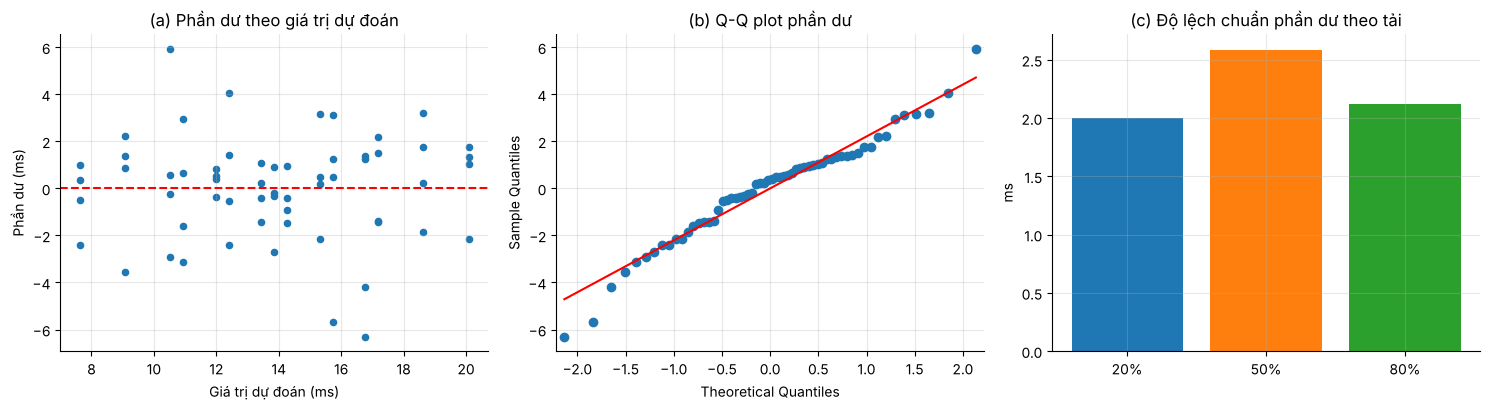

Phần dư có chuẩn không (Shapiro-Wilk):        p = 0.229  ->  đạt
Quan hệ có thẳng không (thiếu khớp, F):       p = 0.955  ->  đạt
Có tương tác x1*x2 không (hệ số x1:x2):      p = 0.648  ->  không có tương tác
Phương sai đều không (Breusch-Pagan):          p = 0.935  ->  đạt
Sai số độc lập: đạt do dữ liệu được sinh với các ε độc lập (theo đề).


In [24]:
res, fit = mo_hinh_boi.resid, mo_hinh_boi.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

ax[0].scatter(fit, res, s=20); ax[0].axhline(0, color="red", ls="--")
ax[0].set(title="(a) Phần dư theo giá trị dự đoán", xlabel="Giá trị dự đoán (ms)", ylabel="Phần dư (ms)")

sm.qqplot(res, line="s", ax=ax[1]); ax[1].set_title("(b) Q-Q plot phần dư")

sd = pd.DataFrame({"x2": df["x2"], "res": res}).groupby("x2")["res"].std()
ax[2].bar([f"{m}%" for m in sd.index], sd.values, color=[MAU[m] for m in sd.index])
ax[2].set(title="(c) Độ lệch chuẩn phần dư theo tải", ylabel="ms")
plt.tight_layout(); plt.show()

# Kiểm định thiếu khớp: mô hình thẳng so với mô hình "mỗi ô một trung bình"
m_o = smf.ols("y ~ C(x1) * C(x2)", data=df).fit()
lof = anova_lm(mo_hinh_boi, m_o)
tuongtac = smf.ols("y ~ x1 * x2", data=df).fit().pvalues["x1:x2"]
print(f"Phần dư có chuẩn không (Shapiro-Wilk):        p = {stats.shapiro(res).pvalue:.3f}  ->  {'đạt' if stats.shapiro(res).pvalue > .05 else 'không đạt'}")
print(f"Quan hệ có thẳng không (thiếu khớp, F):       p = {lof.loc[1,'Pr(>F)']:.3f}  ->  {'đạt' if lof.loc[1,'Pr(>F)'] > .05 else 'không đạt'}")
print(f"Có tương tác x1*x2 không (hệ số x1:x2):      p = {tuongtac:.3f}  ->  {'không có tương tác' if tuongtac > .05 else 'có tương tác'}")

from statsmodels.stats.diagnostic import het_breuschpagan
bp_p = het_breuschpagan(res, mo_hinh_boi.model.exog)[1]
print(f"Phương sai đều không (Breusch-Pagan):          p = {bp_p:.3f}  ->  {'đạt' if bp_p > .05 else 'không đạt'}")
print("Sai số độc lập: đạt do dữ liệu được sinh với các ε độc lập (theo đề).")

**Đọc kết quả:** nếu phần dư (a) rải đều quanh 0 không có hình cong hay hình phễu, (b) các điểm bám đường thẳng, (c) độ lệch chuẩn phần dư xấp xỉ nhau giữa các mức tải, và các $p$ (Shapiro–Wilk, thiếu khớp, tương tác, Breusch–Pagan) đều $>0{,}05$, thì các giả định chuẩn, tuyến tính, không tương tác và phương sai đều được chấp nhận **trong dữ liệu này**. Giả định độc lập thỏa vì các sai số được sinh độc lập theo đề.

### 7.2 Yếu tố thực tế mà mô hình chưa xét
| Yếu tố | Vì sao ảnh hưởng đến độ trễ |
|---|---|
| Số chặng (hop) và khoảng cách | Mỗi chặng thêm thời gian xử lý; khoảng cách xa thì trễ lan truyền lớn |
| Băng thông đường truyền | Tải % chỉ có ý nghĩa khi biết đường truyền lớn hay nhỏ |
| Độ dài hàng đợi, bộ đệm ở router | Nguồn trực tiếp của trễ chờ |
| Mất gói và truyền lại | Phải gửi lại làm trễ tăng, thường có đuôi dài |
| Giao thức, loại đường truyền, giờ cao điểm | Mỗi loại cách xử lý khác nhau |
| Xử lý ở máy chủ | Cộng thêm vào độ trễ đo được |

### 7.3 Vì sao không được dùng mô hình ngoài khoảng 20–80%
Mô hình là đường thẳng. Nhưng theo lý thuyết hàng đợi, khi tải gần 100% thì độ trễ tăng vọt theo dạng cong, không còn thẳng. Hình dưới **chỉ là minh họa lý thuyết, không phải dữ liệu của nhóm**: ta khớp một đường thẳng trên đúng khoảng 20–80% rồi xem nó sai thế nào khi tải lên 90–95%.

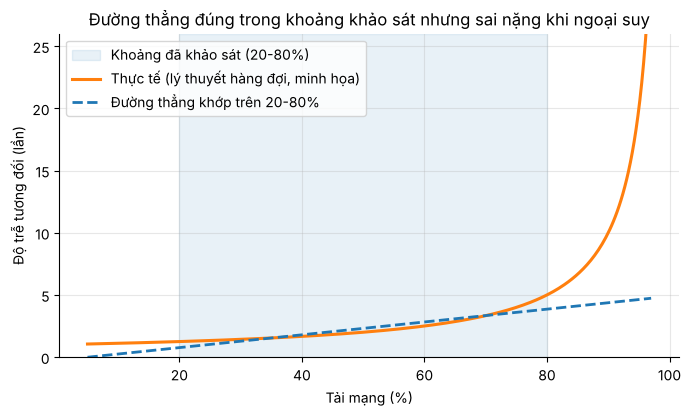

Tại tải 95%: đường thẳng cho 4.6 lần, thực tế 20 lần.


In [25]:
rho = np.linspace(0.05, 0.97, 300); tre = 1 / (1 - rho)                  # trễ tương đối theo lý thuyết hàng đợi M/M/1
trong = (rho >= .2) & (rho <= .8); k1, k0 = np.polyfit(rho[trong], tre[trong], 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axvspan(20, 80, color="tab:blue", alpha=.1, label="Khoảng đã khảo sát (20-80%)")
ax.plot(rho * 100, tre, color="tab:orange", lw=2.2, label="Thực tế (lý thuyết hàng đợi, minh họa)")
ax.plot(rho * 100, k0 + k1 * rho, color="tab:blue", ls="--", lw=2, label="Đường thẳng khớp trên 20-80%")
ax.set(ylim=(0, 26), title="Đường thẳng đúng trong khoảng khảo sát nhưng sai nặng khi ngoại suy", xlabel="Tải mạng (%)", ylabel="Độ trễ tương đối (lần)")
ax.legend(loc="upper left"); plt.show()
print(f"Tại tải 95%: đường thẳng cho {k0 + k1*.95:.1f} lần, thực tế {1/(1-.95):.0f} lần.")

### 7.4 Giới hạn khi áp dụng kết quả
1. **Phạm vi:** chỉ dùng cho gói 200–1400 byte và tải 20–80%. Ngoài khoảng này phải đo thêm.
2. **Dữ liệu mô phỏng:** hệ số chỉ minh họa phương pháp, không phải đặc tính của một mạng thực. Dùng thật thì phải đo lại.
3. **Khoảng dự đoán rộng:** sai số điển hình vài ms, chưa đủ chính xác nếu cần cam kết độ trễ chặt.
4. **Mô hình đơn giản:** giả định tuyến tính và cộng tính; mạng thật thường phi tuyến, có tương tác và nhiễu có đuôi dài.
5. **Cỡ mẫu 60** đủ cho hai hệ số chính nhưng chưa đủ để phát hiện các hiệu ứng nhỏ hơn.

## Kết luận chung

### Trả lời câu hỏi nghiên cứu
(các số được in từ kết quả của lần chạy này)

In [26]:
print("1) Mỗi yếu tố có ảnh hưởng không?")
print(f"   Có. Kích thước gói tin (p = {mo_hinh_boi.pvalues['x1']:.1e}) và tải mạng (p = {mo_hinh_boi.pvalues['x2']:.1e}) đều có ý nghĩa thống kê ở mức 5%.")
print(f"   +100 byte làm độ trễ tăng {100*b1:.2f} ms; +10% tải làm độ trễ tăng {10*b2:.2f} ms (mỗi hệ số tính khi giữ biến kia không đổi).")
print("2) Chỉ dùng kích thước gói tin thì thiếu gì?")
print(f"   R2 hiệu chỉnh chỉ {mo_hinh_don.rsquared_adj:.3f} so với {mo_hinh_boi.rsquared_adj:.3f} của mô hình bội; phần dư tách tầng theo tải (Kruskal-Wallis p = {kw_don.pvalue:.1e});")
print(f"   khoảng dự đoán rộng hơn. Mô hình bội khắc phục được các điểm này (phần dư theo tải p = {kw_boi.pvalue:.2f}).")
print("3) Dự đoán khi gói 1000 byte, tải 60%:")
print(f"   {y0:.1f} ms; một gói cụ thể nằm trong khoảng {pi_lo:.1f} đến {pi_hi:.1f} ms với độ tin cậy 95% (đây là nội suy nên đáng tin).")

1) Mỗi yếu tố có ảnh hưởng không?
   Có. Kích thước gói tin (p = 2.8e-09) và tải mạng (p = 5.3e-13) đều có ý nghĩa thống kê ở mức 5%.
   +100 byte làm độ trễ tăng 0.48 ms; +10% tải làm độ trễ tăng 1.11 ms (mỗi hệ số tính khi giữ biến kia không đổi).
2) Chỉ dùng kích thước gói tin thì thiếu gì?
   R2 hiệu chỉnh chỉ 0.244 so với 0.694 của mô hình bội; phần dư tách tầng theo tải (Kruskal-Wallis p = 1.3e-08);
   khoảng dự đoán rộng hơn. Mô hình bội khắc phục được các điểm này (phần dư theo tải p = 0.65).
3) Dự đoán khi gói 1000 byte, tải 60%:
   15.9 ms; một gói cụ thể nằm trong khoảng 11.3 đến 20.5 ms với độ tin cậy 95% (đây là nội suy nên đáng tin).


### Biến cần thu thập để mô hình tốt hơn
| Biến cần thu thập | Vì sao cần |
|---|---|
| Băng thông / dung lượng đường truyền | Tải 40% trên đường 10 Mbps khác hẳn 40% trên đường 1 Gbps |
| Số chặng và khoảng cách | Quyết định phần trễ lan truyền cố định |
| Độ dài hàng đợi / bộ đệm | Nguyên nhân trực tiếp của trễ chờ, tăng mạnh khi tải cao |
| Tỉ lệ mất gói và số lần truyền lại | Mất gói làm tăng độ trễ |
| Loại giao thức, loại lưu lượng | Mỗi loại được xử lý khác nhau |
| Mức xử lý của máy chủ (CPU) | Cộng thêm vào độ trễ đo được |
| Thời điểm đo (giờ cao điểm) | Tải và độ trễ thay đổi theo thời gian |

Ngoài ra nên đo thêm ở mức tải cao hơn (90–95%) để kiểm tra tính tuyến tính.

In [27]:
print("TÓM TẮT KẾT QUẢ")
print(f"- Mô hình đơn : y = {mo_hinh_don.params['Intercept']:.3f} + {mo_hinh_don.params['x1']:.5f}*x1 ; R2 hiệu chỉnh = {mo_hinh_don.rsquared_adj:.3f}")
print(f"- Mô hình bội : y = {b0:.3f} + {b1:.5f}*x1 + {b2:.4f}*x2 ; R2 hiệu chỉnh = {mo_hinh_boi.rsquared_adj:.3f}")
print(f"- +100 byte -> +{100*b1:.2f} ms ; +10% tải -> +{10*b2:.2f} ms")
print(f"- Dự đoán (1000 byte, 60%): {y0:.2f} ms ; khoảng tin cậy 95% [{ci_lo:.2f} ; {ci_hi:.2f}] ; khoảng dự đoán 95% [{pi_lo:.2f} ; {pi_hi:.2f}]")

TÓM TẮT KẾT QUẢ
- Mô hình đơn : y = 9.978 + 0.00484*x1 ; R2 hiệu chỉnh = 0.244
- Mô hình bội : y = 4.436 + 0.00484*x1 + 0.1108*x2 ; R2 hiệu chỉnh = 0.694
- +100 byte -> +0.48 ms ; +10% tải -> +1.11 ms
- Dự đoán (1000 byte, 60%): 15.93 ms ; khoảng tin cậy 95% [15.24 ; 16.62] ; khoảng dự đoán 95% [11.34 ; 20.52]


## Phụ lục. Đánh giá phương pháp bằng cách so sánh với giá trị thật

Đề cho phép dùng các tham số tạo dữ liệu **chỉ để đánh giá phương pháp**. Ở các bước trên, nhóm đã ước lượng hoàn toàn từ mẫu. Bây giờ mới đem so sánh với giá trị thật dùng để sinh dữ liệu: nếu phương pháp tốt thì khoảng tin cậy 95% phải chứa giá trị thật.

In [28]:
THAT = {"Intercept": 5.0, "x1": 0.005, "x2": 0.1}          # chỉ dùng ở đây để đánh giá, không dùng ở các bước ước lượng
bang_so = pd.DataFrame({
    "Giá trị thật": pd.Series(THAT),
    "Ước lượng": mo_hinh_boi.params,
    "CI 95% dưới": ci[0], "CI 95% trên": ci[1],
})
bang_so["CI chứa giá trị thật?"] = np.where((bang_so["CI 95% dưới"] <= bang_so["Giá trị thật"]) & (bang_so["Giá trị thật"] <= bang_so["CI 95% trên"]), "Có", "Không")
display(bang_so.round(5))
print(f"Độ lệch chuẩn sai số: thật = 2,   ước lượng s = {mo_hinh_boi.mse_resid**0.5:.3f}")

,Giá trị thật,Ước lượng,CI 95% dưới,CI 95% trên,CI chứa giá trị thật?
Intercept,5.000,4.43622,2.70704,6.16540,Có
x1,0.005,0.00484,0.00346,0.00622,Có
x2,0.100,0.11083,0.08693,0.13474,Có


Độ lệch chuẩn sai số: thật = 2,   ước lượng s = 2.265


**Kết luận phụ lục:** nếu cả ba khoảng tin cậy đều chứa giá trị thật và $s$ gần 2, thì quy trình ước lượng của nhóm cho kết quả đúng với dữ liệu này. Lưu ý đây là kết quả của **một** mẫu; một khoảng tin cậy 95% vẫn có khoảng 5% khả năng không chứa giá trị thật.